# A supernova in its host galaxy: NGC hosts at redshift

The Sersic hosts of notebook 07 are angular: `r_eff` in arcsec, a total
magnitude, no distance. This notebook does the slicersim picture instead: a SN
Ia at redshift $z$ in a **real galaxy** moved to that $z$, with the galaxy's own
spectrum and absolute magnitude. One `redshift` on the scene drives everything:

- the spectra of source and host are stretched by $1+z$;
- the brightness follows a rest-frame absolute magnitude (`magabs`) through the
  distance modulus (Planck18), K-corrected through the template's own shape;
- the galaxy keeps its physical size, so its image shrinks on the sky with
  distance (angular-diameter-distance ratio).

The galaxy images and spectra come from the `lazuli_astrosim_data` package
(76 NGC galaxies, r-band thumbnails). `host="ngc0628"` means the image **and**
the spectrum of NGC 0628.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import wcc_etc
from wcc_etc import Simulation, get_scene
from wcc_etc.psfsim import ImageSimulator

wcc_etc.set_wcc_style()

SENSOR = "zwo:r"  # in-focus r band on the IMX455
TIME = 300.0  # seconds
NPIX = 256  # 256 px = 4.3 arcsec on a side
Z = 0.9


def sn_in_host(redshift=Z, host="ngc0628", **host_prop):
    """A SN Ia (hsiao07 template, M = -19.3 AB in sdss r) in an NGC host at one redshift."""
    return get_scene(
        "hsiao07", mag=None, magabs=-19.3, redshift=redshift,
        bandpass="sdss_r", magsys="abmag",
        host=host, host_prop={"dx": 0.4, "dy": -0.2, "pa": 30} | host_prop,
    )


scene = sn_in_host()
sim = Simulation.from_sensorfilter(SENSOR, scene)
PLATE = ImageSimulator(sim).plate_scale_mas / 1000  # arcsec / pixel
print(f"plate scale        {PLATE:.4f} arcsec/px")
print(f"SN observed mag    {scene.source.mag:.2f}  (M = -19.3, z = {Z})")
print(f"host observed mag  {scene.host.mag:.2f}  (M = -21, z = {Z})")
print("host profile      ", scene.host.profile)

plate scale        0.0169 arcsec/px
SN observed mag    24.43 mag(AB)  (M = -19.3, z = 0.9)
host observed mag  23.65 mag(AB)  (M = -21, z = 0.9)
host profile       {'model': 'ngc', 'name': 'ngc0628', 'redshift': 0.9, 'dx': 0.4, 'dy': -0.2, 'pa': 30}


## 1. The galaxy on the sky at different redshifts

`SceneElement.show_image` renders the spatial model alone (no PSF) on a detector
grid. The same galaxy at $z$ = 0.1, 0.3 and 0.9: the physical size is fixed, so
the angular size shrinks (slowly beyond $z \sim 1$, where the angular diameter
distance flattens). The nucleus sits 0.4" right and 0.2" below the grid centre,
where the SN is; the image is rotated by 30 degrees.

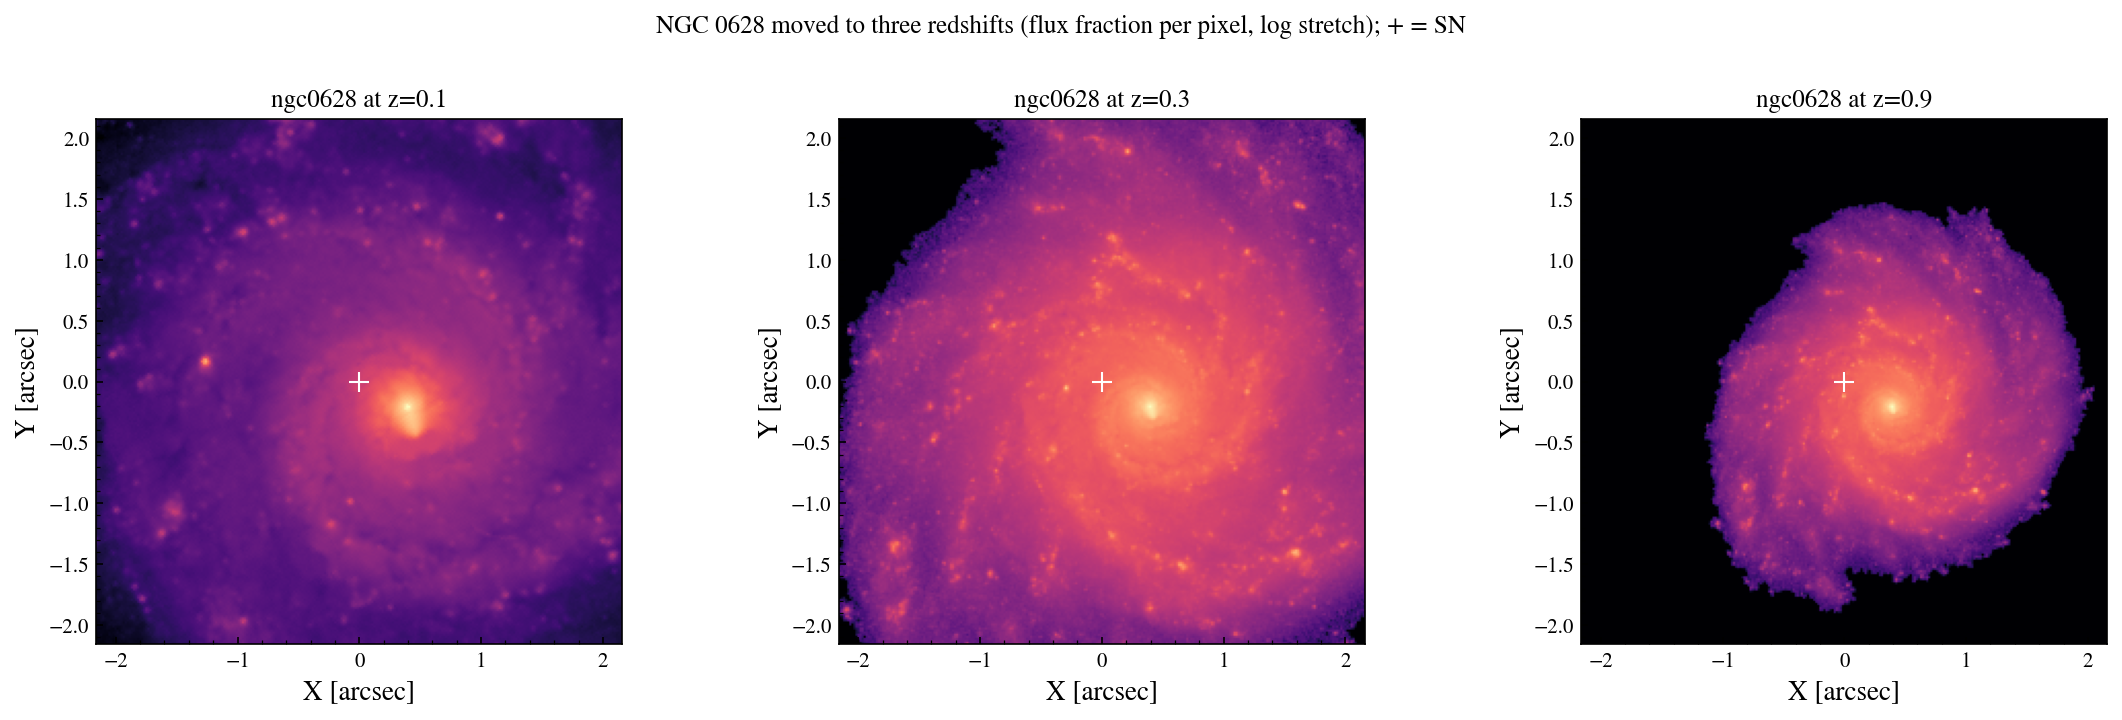

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, z in zip(axes, [0.1, 0.3, Z]):
    sn_in_host(redshift=z).host.show_image(
        PLATE, npix=NPIX, ax=ax, units="arcsec", cmap="magma", colorbar=False
    )
    ax.plot(0, 0, "+", color="w", ms=10, mew=1)
fig.suptitle("NGC 0628 moved to three redshifts (flux fraction per pixel, log stretch); + = SN", y=1.02)
fig.tight_layout()
plt.show()

## 2. The simulated frame and the host under the transient

`Simulation.plot_host` draws one noisy 300 s realization of the whole scene
(SN + host + zodi) next to the PSF-convolved host alone, i.e. the galaxy light
that lands under the SN.

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


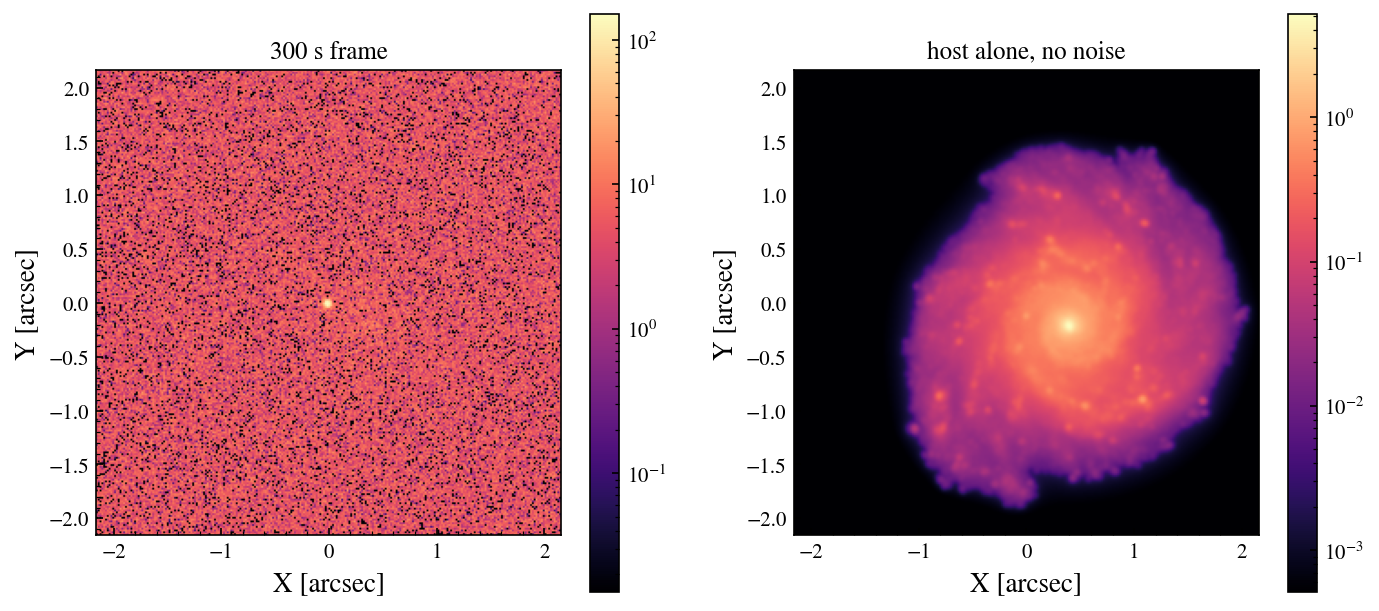

In [3]:
fig, axes = sim.plot_host(TIME, npix=NPIX, units="arcsec", cmap="magma")
plt.show()

## 3. The spectra

Both templates are stretched by $1+z$ = 1.9. The SN Ia rest-frame optical lands
in the near infrared, so in the r band the WCC sees its rest-frame UV; the host
template (NGC 0628's own spectrum) is treated the same way.

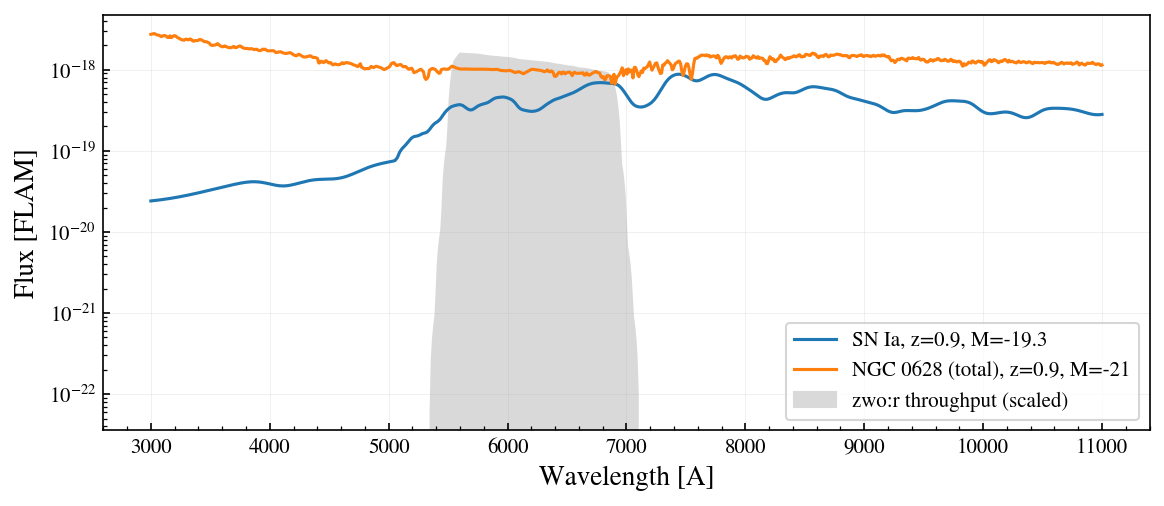

In [4]:
wave = np.linspace(3000, 11000, 800)
fig, ax = plt.subplots(figsize=(9, 3.6))
scene.source.show(ax=ax, wave=wave, flux_unit="flam", label=f"SN Ia, z={Z}, M=-19.3")
scene.host.show(ax=ax, wave=wave, flux_unit="flam", label=f"NGC 0628 (total), z={Z}, M=-21")
band = sim.sensor.bandpass
ax.fill_between(wave, 0, band(wave).value * ax.get_ylim()[1], color="0.85", zorder=0, label="zwo:r throughput (scaled)")
ax.set_yscale("log")
ax.legend()
plt.show()

## 4. What the host costs: SNR against offset from the nucleus

The host adds flux and photon noise under the SN aperture. `get_image_snr`
(PSF-aware, with the host rendered and convolved) with and without the galaxy,
then the SN moved from the nucleus into the outskirts.

SNR in 300 s:  with host 32.2   without host 32.3


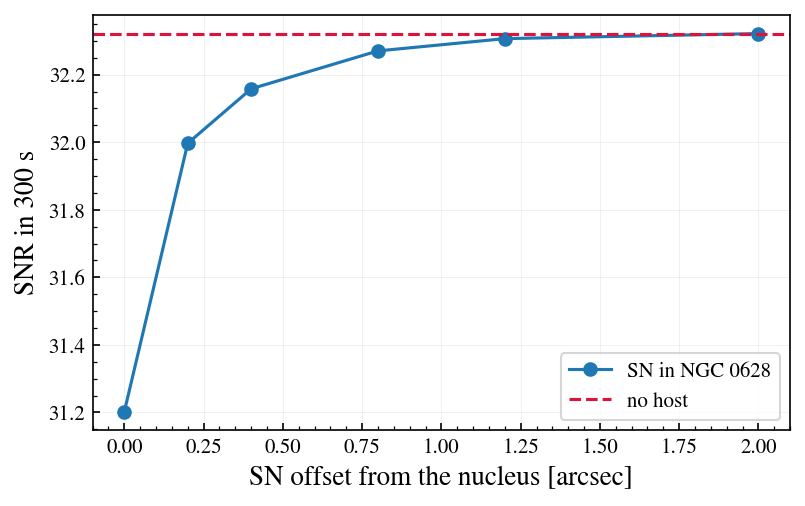

In [5]:
with_host = sim.get_image_snr(TIME)
no_host = Simulation.from_sensorfilter(
    SENSOR, get_scene("hsiao07", mag=None, magabs=-19.3, redshift=Z,
                      bandpass="sdss_r", magsys="abmag", host=None)
).get_image_snr(TIME)
print(f"SNR in {TIME:.0f} s:  with host {with_host['snr']:.1f}   without host {no_host['snr']:.1f}")

offsets = np.array([0.0, 0.2, 0.4, 0.8, 1.2, 2.0])
snr = [
    Simulation.from_sensorfilter(SENSOR, sn_in_host(dx=dx, dy=0.0, pa=0)).get_image_snr(TIME)["snr"]
    for dx in offsets
]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(offsets, snr, "o-", label="SN in NGC 0628")
ax.axhline(no_host["snr"], color="crimson", ls="--", label="no host")
ax.set_xlabel("SN offset from the nucleus [arcsec]")
ax.set_ylabel(f"SNR in {TIME:.0f} s")
ax.legend()
plt.show()

## 5. A Sersic host sized in kpc

The analytic host of notebook 07 can be sized physically too: `r_kpc` with a
`redshift` gives `r_eff` in arcsec through `arcsec_per_kpc_proper(z)`, and
`magabs` sets its brightness. A 5 kpc, $n$ = 2 disk at $z$ = 0.9 with a G5V-like
spectrum, next to the NGC image at the same redshift.

r_eff = 0.624 arcsec for 5 kpc at z = 0.9


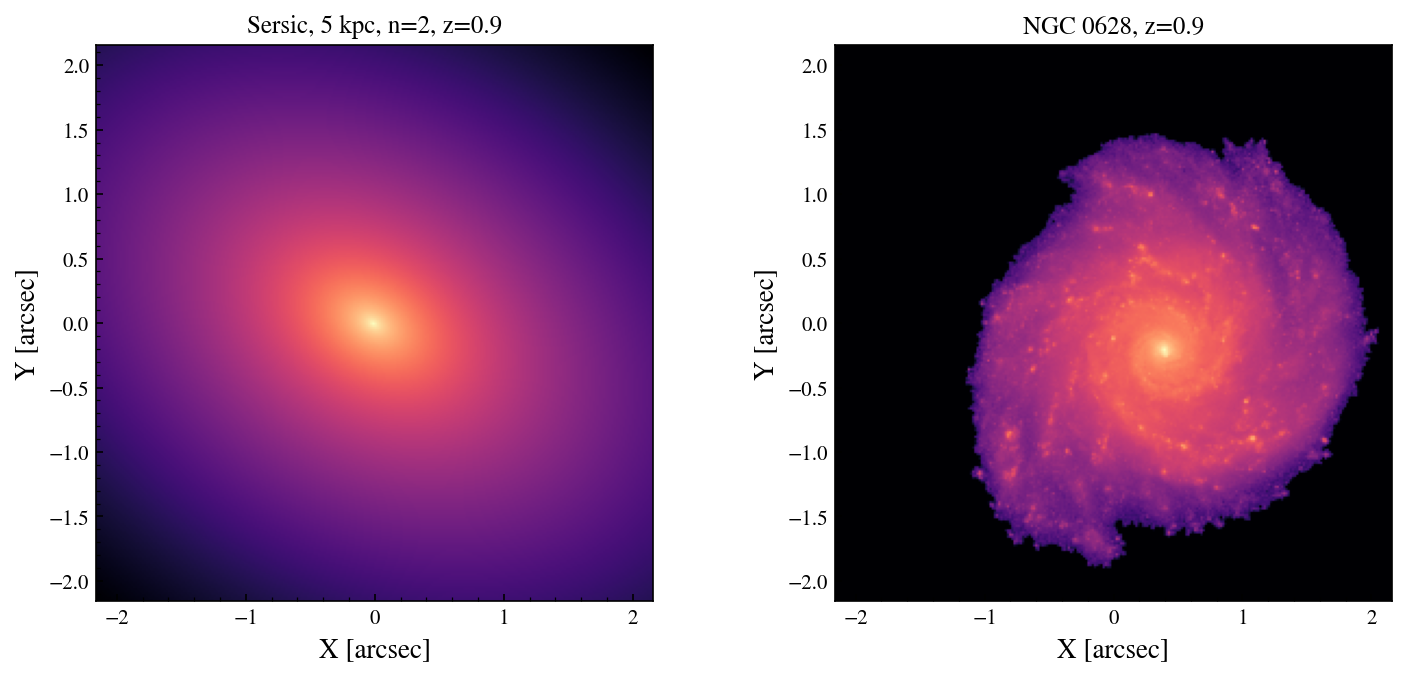

In [6]:
sersic = get_scene(
    "hsiao07", mag=None, magabs=-19.3, redshift=Z, bandpass="sdss_r", magsys="abmag",
    host="G5V",
    host_prop={"profile": "sersic", "r_kpc": 5, "n": 2, "ellip": 0.3, "pa": -30,
               "mag": None, "magabs": -21, "bandpass": "sdss_r", "magsys": "abmag"},
)
print(f"r_eff = {sersic.host.profile['r_eff']:.3f} arcsec for 5 kpc at z = {Z}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
sersic.host.show_image(PLATE, npix=NPIX, ax=axes[0], units="arcsec", cmap="magma", colorbar=False, title="Sersic, 5 kpc, n=2, z=0.9")
scene.host.show_image(PLATE, npix=NPIX, ax=axes[1], units="arcsec", cmap="magma", colorbar=False, title="NGC 0628, z=0.9")
fig.tight_layout()
plt.show()

## Summary

- `host="ngc0628"` with a `redshift` is a real galaxy moved to that redshift:
  its own image (`profile`) and spectrum, `magabs=-21` in sdss r (AB) by default,
  physical size kept. `dx`, `dy` (arcsec) and `pa` (degrees) place and rotate it.
- `redshift` and `magabs` work on any element, so the transient (here the
  hsiao07 SN Ia template) follows the same distance.
- `get_scene(..., redshift=z)` hands the redshift to the host unless `host_prop`
  sets its own. Sersic hosts accept `r_kpc`.
- `scene.host.show_image(plate_scale)` shows the host alone; `sim.plot_host(time)`
  the simulated frame next to the host under the transient.